# AIP201TC Coursework 1 - Skeleton Notebook

Fill in every `# TODO` code cell and every `Answer:` line below it. Read `AIP201TC_CW1_Coursework.pdf` first for the full task list and how each part is assessed.

- Keep every answer inside its word limit.
- Numeric fill-in-the-blank answers stay as markdown too. Type the number directly, do not change the bold label in front of it.
- Fill-in-the-blank numeric answers stay as plain markdown text.

## 0. Environment Setup

Set this up yourself and write down what you did.

- Use `pip` or `conda` to install libraries under a conda environment. An offline wheel install also works if you have no internet access on the lab machine.
- You will need (at least): `torch`, `torchvision`, `numpy`, `matplotlib`, `scikit-learn`.

**Your environment notes:**
- Answer: The notebook was configured on a local Windows computer in the conda environment `aip201tc`, using Python 3.12.15. Dependencies were installed using pip to install libraries from requirements.txt and else install matplotlib. The imported library versions were PyTorch 2.5.1+cu121, torchvision 0.20.1+cu121, NumPy 2.4.3, scikit-learn 1.9.0, and Matplotlib 3.11.2. The code checks CUDA availability and selects a GPU when available, otherwise falling back to the CPU. On this computer, CUDA was available, and the selected device was an NVIDIA GeForce RTX 4060 Laptop GPU.

In [1]:
# Environment: library versions and device selection

# Import the libraries used below and record their installed versions.
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import copy
import torchvision
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import json

print('torch version:', torch.__version__)
print('torchvision version:', torchvision.__version__)
print('numpy version:', np.__version__)
print('scikit-learn version:', sklearn.__version__)
print('matplotlib version:', matplotlib.__version__)

# Select the device at runtime so the same code can use a GPU or CPU.
cuda_available = torch.cuda.is_available()
print('CUDA available:', cuda_available)

if cuda_available:
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print('Selected device:', device)

if cuda_available:
    print('GPU:', torch.cuda.get_device_name(0))


torch version: 2.5.1+cu121
torchvision version: 0.20.1+cu121
numpy version: 2.4.3
scikit-learn version: 1.9.0
matplotlib version: 3.11.2
CUDA available: True
Selected device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Personalized Seed Mechanism

Replace the student ID with your ID. Do not modify other parts of this cell.

In [2]:
import hashlib

def get_seed(student_id: str, salt: int = 0) -> int:
    h = hashlib.sha256(f"{student_id}_{salt}".encode()).hexdigest()
    return int(h, 16) % (2**32)

STUDENT_ID = "2468905"
SEED_SPLIT  = get_seed(STUDENT_ID, salt=0)
SEED_TASK1  = get_seed(STUDENT_ID, salt=1)
SEED_TASK2  = get_seed(STUDENT_ID, salt=2)

print("SEED_SPLIT  =", SEED_SPLIT)
print("SEED_TASK1  =", SEED_TASK1)
print("SEED_TASK2  =", SEED_TASK2)

torch.manual_seed(SEED_SPLIT)


SEED_SPLIT  = 1615181162
SEED_TASK1  = 2526213120
SEED_TASK2  = 1877505316


## 2. Load Fashion-MNIST

The data loading code is given. Of course, you may change this cell based on your needs.


In [3]:
# Data: load Fashion-MNIST and create the personalised split

import os
import torch
import numpy as np
from torchvision.datasets import FashionMNIST
from torchvision import transforms

# Keep the dataset path relative to the notebook working directory.
DATA_ROOT = "./data"
os.makedirs(DATA_ROOT, exist_ok=True)

# ToTensor converts each image to a float tensor with values in [0, 1].
train_full = FashionMNIST(
    DATA_ROOT, train=True, download=True,
    transform=transforms.ToTensor()
)
test_set = FashionMNIST(
    DATA_ROOT, train=False, download=True,
    transform=transforms.ToTensor()
)

# Keep the tensors on the CPU; the training loop moves each batch as needed.
X_all = torch.stack([img for img, _ in train_full])
y_all = torch.tensor([lbl for _, lbl in train_full])
X_test = torch.stack([img for img, _ in test_set])
y_test = torch.tensor([lbl for _, lbl in test_set])

# Use a separate generator so the split depends only on the student seed.
gen = torch.Generator().manual_seed(SEED_SPLIT)
idx = torch.randperm(len(X_all), generator=gen)

# Reserve 15% of the original training set for validation.
n_val = int(0.15 * len(X_all))

X_val, y_val = X_all[idx[:n_val]], y_all[idx[:n_val]]
X_train, y_train = X_all[idx[n_val:]], y_all[idx[n_val:]]

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")


Train: torch.Size([51000, 1, 28, 28]), Val: torch.Size([9000, 1, 28, 28]), Test: torch.Size([10000, 1, 28, 28])


---
# Task 1: Build and Understand an MLP

## Task 1-1: Data Processing and Modelling

- Please follow the CW1 PDF description to implement the MLP, as well as the training & evaluation bits.
- Run `report_task1_1()` at the end to produce the actual output on the screen. It also writes your test accuracy separately to `results.json`.

In [4]:
# Task 1-1: standardise inputs using training statistics

# Estimate both statistics from training pixels only to avoid data leakage.
train_mean = X_train.mean()
train_std = X_train.std()
print('Training mean before standardization:', train_mean.item())
print('Training standard deviation:', train_std.item())

# Use the same transformation for all three splits.
X_train = (X_train - train_mean) / train_std
print("Mean after standardization:", X_train.mean().item())
print("Std after standardization:", X_train.std().item())
print("Training shape:", X_train.shape)

# Validation statistics need not be exactly zero and one after this step.
X_val = (X_val - train_mean) / train_std
print("Validation mean:", X_val.mean().item())
print("Validation std:", X_val.std().item())
print("Validation shape:", X_val.shape)

# Keep the test set separate from fitting and checkpoint selection.
X_test = (X_test - train_mean) / train_std
print("Test mean:", X_test.mean().item())
print("Test std:", X_test.std().item())
print("Test shape:", X_test.shape)


Training mean before standardization: 0.28597426414489746
Training standard deviation: 0.3528798222541809
Mean after standardization: -3.639150847334349e-08
Std after standardization: 1.0
Training shape: torch.Size([51000, 1, 28, 28])
Validation mean: 0.001253294525668025
Validation std: 1.0027250051498413
Validation shape: torch.Size([9000, 1, 28, 28])
Test mean: 0.0024796328507363796
Test std: 0.9987654685974121
Test shape: torch.Size([10000, 1, 28, 28])


**Your data processing note:**
- Answer:Pixel values were scaled to [0, 1] using ToTensor(). I then computed the mean (approximately 0.285974) and standard deviation (approximately 0.352880) across all training-set pixels. I standardized the training, validation and test inputs by subtracting this training-set mean and dividing by this training-set standard deviation.

In [5]:
# Task 1-1: define the MLP

class MLP(nn.Module):
    def __init__(self, input_dim=784, num_classes=10, hidden=128):
        super().__init__()

        # Flatten each image while preserving the batch dimension.
        self.flatten = nn.Flatten(start_dim=1)

        # Use one hidden layer with 128 units by default, followed by ReLU.
        self.fc1 = nn.Linear(input_dim, hidden)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)

        # Return logits; CrossEntropyLoss handles their normalisation during training.
        x = self.fc2(x)
        return x


In [6]:
# Training: share one training loop across all experiments

from torch.utils.data import TensorDataset, DataLoader
import copy


def train_model(
    model,
    X_tr,
    y_tr,
    X_va,
    y_va,
    epochs=25,
    lr=1e-3,
    batch_size=64,
    record_grad_norm_layer=None,
    weight_decay=0.0
):
    # Move the model once, then transfer only the batches needed for each step.
    model = model.to(device)

    train_dataset = TensorDataset(X_tr, y_tr)
    val_dataset = TensorDataset(X_va, y_va)

    # Shuffle training samples each epoch; validation does not need shuffling.
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    # Cross-entropy takes raw logits and integer class labels.
    criterion = nn.CrossEntropyLoss()

    # A non-zero weight_decay enables the L2 experiment with Adam.
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    # Store one loss value per epoch for the later plots and comparisons.
    history = {
        "train_loss": [],
        "val_loss": []
    }

    # Record gradients only when a layer is supplied.
    if record_grad_norm_layer is not None:
        history["grad_norm"] = []

    # Select checkpoints using validation loss, without consulting the test set.
    best_val_loss = float("inf")
    best_state = None
    best_epoch = None

    for epoch in range(epochs):
        # Training mode enables dropout and updates BatchNorm running statistics.
        model.train()
        train_loss_sum = 0.0
        epoch_grad_norms = []

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Clear the previous batch gradients before backpropagation.
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()

            if record_grad_norm_layer is not None:
                # Measure the layer gradient after backward and before the parameter
                # update.
                parameter_grad_norms = [
                    p.grad.detach().norm(2)
                    for p in record_grad_norm_layer.parameters()
                    if p.grad is not None
                ]

                if not parameter_grad_norms:
                    raise RuntimeError(
                        "No gradients found in the selected layer."
                    )

                # Combine the parameter norms into one L2 norm for this layer.
                layer_grad_norm = torch.stack(
                    parameter_grad_norms
                ).norm(2).item()

                epoch_grad_norms.append(layer_grad_norm)

            optimizer.step()

            # Weight by batch size so the smaller final batch is counted correctly.
            train_loss_sum += loss.item() * inputs.size(0)

        train_loss = train_loss_sum / len(train_dataset)

        # Validation uses stored BatchNorm statistics and disables dropout.
        model.eval()
        val_loss_sum = 0.0

        # Validation needs predictions only, so no gradient graph is retained.
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * inputs.size(0)

        val_loss = val_loss_sum / len(val_dataset)

        # Keep training and validation records aligned by epoch.
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if record_grad_norm_layer is not None:
            history["grad_norm"].append(
                sum(epoch_grad_norms) / len(epoch_grad_norms)
            )

        # Copy the checkpoint so later updates cannot overwrite the saved tensors.
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f}"
        )

    # Restore the best validation checkpoint after all epochs have finished.
    model.load_state_dict(best_state)
    model.eval()

    history["best_epoch"] = best_epoch
    history["best_val_loss"] = best_val_loss

    return model, history


In [7]:
# Task 1-1: initialise and train the MLP

# Reset the seed before initialising the weights.
torch.manual_seed(SEED_TASK1)

mlp_model = MLP(
    input_dim=784,
    num_classes=10,
    hidden=128
)

# The returned model contains the checkpoint selected by validation loss.
mlp_model, mlp_history = train_model(
    model=mlp_model,
    X_tr=X_train,
    y_tr=y_train,
    X_va=X_val,
    y_va=y_val,
    epochs=25,
    lr=1e-3,
    batch_size=64
)


Epoch 1/25 | Train loss: 0.4829 | Val loss: 0.4055


Epoch 2/25 | Train loss: 0.3677 | Val loss: 0.3423


Epoch 3/25 | Train loss: 0.3262 | Val loss: 0.3362


Epoch 4/25 | Train loss: 0.3014 | Val loss: 0.3225


Epoch 5/25 | Train loss: 0.2826 | Val loss: 0.3242


...

Epoch 21/25 | Train loss: 0.1447 | Val loss: 0.3693


Epoch 22/25 | Train loss: 0.1433 | Val loss: 0.3863


Epoch 23/25 | Train loss: 0.1360 | Val loss: 0.3753


Epoch 24/25 | Train loss: 0.1304 | Val loss: 0.3749


Epoch 25/25 | Train loss: 0.1273 | Val loss: 0.3838


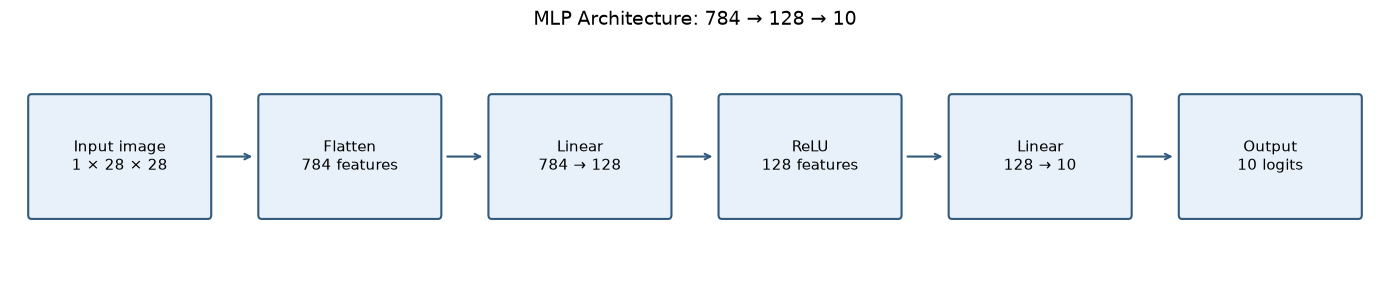

In [8]:
# Task 1-1: show the MLP architecture

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 3))

# Show the implemented layer sizes rather than the learned parameter values.
labels = [
    "Input image\n1 × 28 × 28",
    "Flatten\n784 features",
    "Linear\n784 → 128",
    "ReLU\n128 features",
    "Linear\n128 → 10",
    "Output\n10 logits"
]

box_width = 1.65
box_height = 0.9
spacing = 2.15

# Lay out the layers from left to right and connect the forward path.
for i, label in enumerate(labels):
    x = i * spacing

    box = FancyBboxPatch(
        (x, 0.5),
        box_width,
        box_height,
        boxstyle="round,pad=0.03",
        facecolor="#E8F1FA",
        edgecolor="#315A7D",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        x + box_width / 2,
        0.5 + box_height / 2,
        label,
        ha="center",
        va="center",
        fontsize=11
    )

    if i < len(labels) - 1:
        ax.annotate(
            "",
            xy=((i + 1) * spacing - 0.06, 0.95),
            xytext=(x + box_width + 0.06, 0.95),
            arrowprops={
                "arrowstyle": "->",
                "color": "#315A7D",
                "lw": 1.5
            }
        )

ax.set_xlim(-0.2, (len(labels) - 1) * spacing + box_width + 0.2)
ax.set_ylim(0, 1.9)

ax.set_title("MLP Architecture: 784 → 128 → 10", fontsize=14)
ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:
def report_task1_1(model, X_te, y_te, history):
    """Given. Do not modify."""
    model.eval()
    with torch.no_grad():
        out = model(X_te.to(device))
        test_acc = (out.argmax(1) == y_te.to(device)).float().mean().item()
    try:
        with open("results.json") as f:
            results = json.load(f)
    except FileNotFoundError:
        results = {}
    results["task1_1_test_acc"] = test_acc
    with open("results.json", "w") as f:
        json.dump(results, f, indent=2)
    print(f"Task 1-1 test accuracy: {test_acc:.4f} (written to results.json)")
    return test_acc

# Evaluate the selected MLP checkpoint with the supplied reporting function.
mlp_test_acc = report_task1_1(
    model=mlp_model,
    X_te=X_test,
    y_te=y_test,
    history=mlp_history
)

Task 1-1 test accuracy: 0.8792 (written to results.json)


In [10]:
# Task 1-1: inspect the selected checkpoint and training records

# Check that the history contains all epochs and identifies the selected model.
print("Model:", mlp_model)
print("Training epochs:", len(mlp_history["train_loss"]))
print("Validation epochs:", len(mlp_history["val_loss"]))
print("Best epoch:", mlp_history["best_epoch"])
print("Best validation loss:", mlp_history["best_val_loss"])
print("Training losses:", mlp_history["train_loss"])
print("Validation losses:", mlp_history["val_loss"])


Model: MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Training epochs: 25
Validation epochs: 25
Best epoch: 8
Best validation loss: 0.3089853955639733
Training losses: [0.4829038553939146, 0.3676579685678669, 0.3262310161403581, 0.3014328089788848, 0.28258668045436636, 0.26871403731084337, 0.2531113838074254, 0.24084256588010228, 0.23003253191358902, 0.2183676296192057, 0.21084199244835797, 0.20232760627596985, 0.19669523058919344, 0.18689904288217132, 0.1798395488238802, 0.17693736004712535, 0.1674569489570225, 0.16365072711308798, 0.15570066738479277, 0.15031906611545412, 0.14471601108242485, 0.14332895203548318, 0.1359903451391295, 0.13039799433595994, 0.12732420074238496]
Validation losses: [0.40547358089023167, 0.3423068492677477, 0.33617456454700895, 0.3224860859447055, 0.32423994604746503, 0.31455662462446426, 0.33033307758967084, 0.30

## Task 1-2: Structured Diagnosis

**Plot your loss curves, and use the plots to classify the behavior of your model as underfitting, appropriately fitting, or overfitting.**
- Answer:The model showed overfitting during the later training epochs.

**Evidence** (at most 60 words):
- Answer:Validation loss reached its minimum of approximately 0.31 at epoch 8, then fluctuated upwards to approximately 0.38 by epoch 25. Over the same interval, training loss decreased from approximately 0.24 to 0.13. This widening gap indicates that further training improved the fit to training data while worsening validation performance.

Training records: 25
Validation records: 25


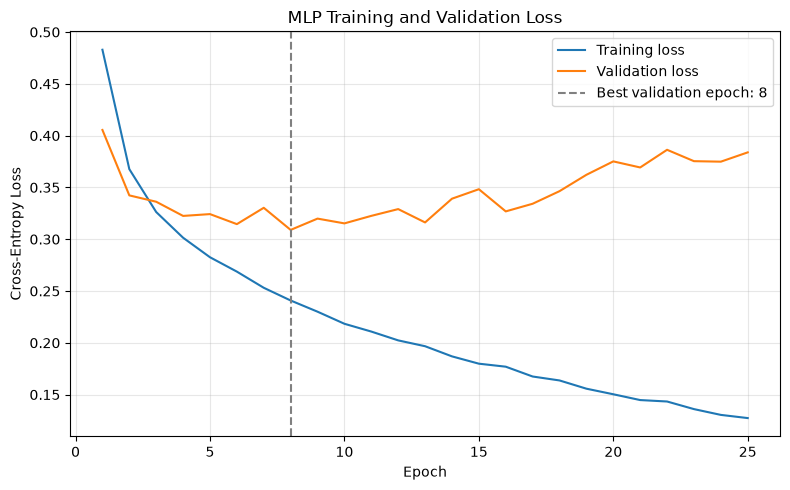

In [11]:
# Task 1-2: plot training and validation loss

# Reuse the recorded losses; plotting does not retrain the model.
train_losses = mlp_history["train_loss"]
val_losses = mlp_history["val_loss"]

print("Training records:", len(train_losses))
print("Validation records:", len(val_losses))

epochs = range(1, len(train_losses) + 1)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    epochs,
    train_losses,
    label="Training loss",
    color="tab:blue"
)

ax.plot(
    epochs,
    val_losses,
    label="Validation loss",
    color="tab:orange"
)

ax.set_title("MLP Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy Loss")


# Mark the checkpoint used for testing, rather than the final training epoch.
ax.axvline(
    x=mlp_history["best_epoch"],
    color="gray",
    linestyle="--",
    label=f"Best validation epoch: {mlp_history['best_epoch']}"
)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Task 1-3: Reflecting on Your Result

A well-implemented MLP on this dataset can typically reach 85% or higher on the test set. However, this is a reference point, not a pass/fail threshold.

**State whether your MLP model achieved at least 85% test-set accuracy. If not, explain the potential reasons from what you observed.** (at most 60 words)
- Answer:My MLP achieved a test accuracy of 87.92%, exceeding the 85% reference by 2.92 percentage points. However, the loss curves showed overfitting during later epochs: training loss continued to decrease while validation loss generally increased after epoch 8.

**Describe how you selected the model for testing and explain whether the selected model is necessarily the best-performing model on the test set.** (at most 60 words)
- Answer:I selected the checkpoint with the lowest validation loss across 25 epochs, which occurred at epoch 8, and restored its parameters before testing. This does not guarantee the highest test accuracy because validation loss and test accuracy measure different aspects of performance on different datasets. The test set was not used for checkpoint selection.

---
# Task 2: Extend to CNN

## Task 2-1: Coding

- Please follow the CW1 PDF description to implement the CNN.
- Reuse `train_model(...)` from Task 1. Do not redefine it.
- Run `report_task2_1()` at the end.

In [12]:
# Task 2-1: define the CNN

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Padding keeps the spatial size unchanged within each convolution.
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            stride=1,
            padding=1
        )

        # Normalise each output channel before applying the activation.
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            stride=1,
            padding=1
        )
        self.bn2 = nn.BatchNorm2d(32)

        self.relu = nn.ReLU()

        # Each pooling operation halves the height and width.
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.flatten = nn.Flatten(start_dim=1)

        # Two pooling operations reduce 28 x 28 to 7 x 7.
        self.fc = nn.Linear(32 * 7 * 7, num_classes)

    def forward(self, x):
        # First block: 1 x 28 x 28 becomes 16 x 14 x 14.
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Second block: 16 x 14 x 14 becomes 32 x 7 x 7.
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Flatten the feature maps and return one logit per class.
        x = self.flatten(x)
        x = self.fc(x)

        return x


In [13]:
# Task 2-1: initialise and train the CNN

# Use the CNN seed before initialisation for the later controlled comparisons.
torch.manual_seed(SEED_TASK2)
cnn_model = SimpleCNN(num_classes=10)

# Reuse the same training and checkpoint-selection procedure as the MLP.
cnn_model, cnn_history = train_model(
    model=cnn_model,
    X_tr=X_train,
    y_tr=y_train,
    X_va=X_val,
    y_va=y_val,
    epochs=25,
    lr=1e-3,
    batch_size=64
)

# Confirm that all epochs were recorded and the best checkpoint was selected.
print("Training records:", len(cnn_history["train_loss"]))
print("Validation records:", len(cnn_history["val_loss"]))
print("Best epoch:", cnn_history["best_epoch"])
print(f"Best validation loss: {cnn_history['best_val_loss']:.4f}")


Epoch 1/25 | Train loss: 0.4094 | Val loss: 0.2983


Epoch 2/25 | Train loss: 0.2902 | Val loss: 0.2669


Epoch 3/25 | Train loss: 0.2573 | Val loss: 0.2567


Epoch 4/25 | Train loss: 0.2366 | Val loss: 0.2955


Epoch 5/25 | Train loss: 0.2184 | Val loss: 0.2615


...

Epoch 21/25 | Train loss: 0.1118 | Val loss: 0.3053


Epoch 22/25 | Train loss: 0.1095 | Val loss: 0.3082


Epoch 23/25 | Train loss: 0.1059 | Val loss: 0.3103


Epoch 24/25 | Train loss: 0.1040 | Val loss: 0.3142


Epoch 25/25 | Train loss: 0.0993 | Val loss: 0.3259
Training records: 25
Validation records: 25
Best epoch: 7
Best validation loss: 0.2462


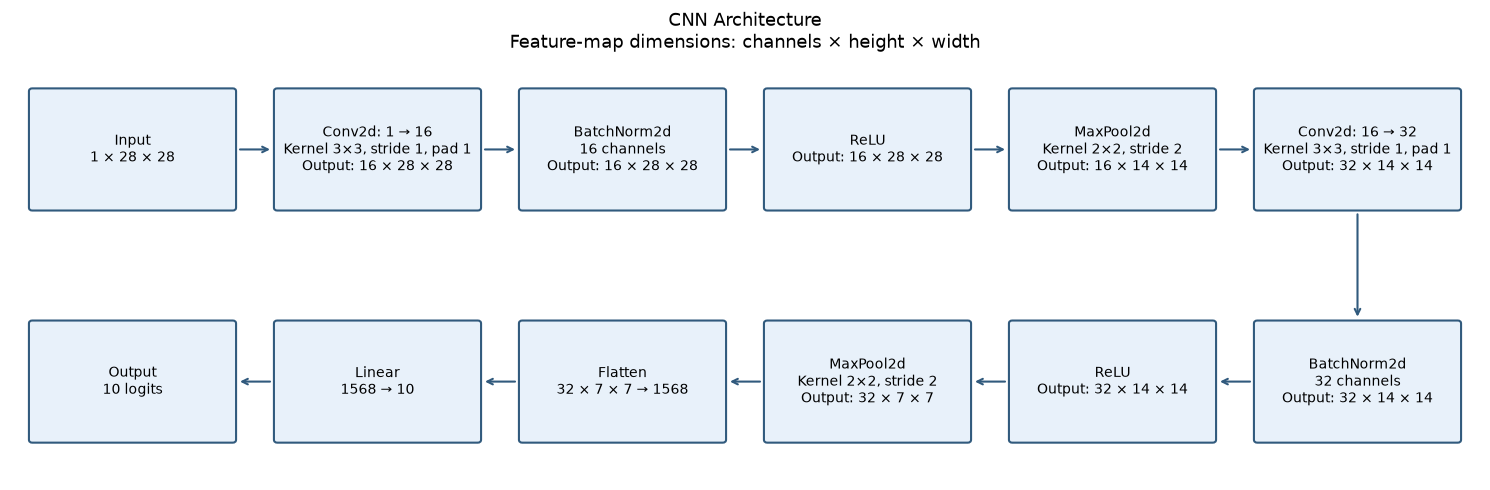

In [14]:
# Task 2-1: show the CNN architecture

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 5))

# Feature-map dimensions are written as channels x height x width.
labels = [
    "Input\n1 × 28 × 28",
    "Conv2d: 1 → 16\nKernel 3×3, stride 1, pad 1\nOutput: 16 × 28 × 28",
    "BatchNorm2d\n16 channels\nOutput: 16 × 28 × 28",
    "ReLU\nOutput: 16 × 28 × 28",
    "MaxPool2d\nKernel 2×2, stride 2\nOutput: 16 × 14 × 14",
    "Conv2d: 16 → 32\nKernel 3×3, stride 1, pad 1\nOutput: 32 × 14 × 14",
    "BatchNorm2d\n32 channels\nOutput: 32 × 14 × 14",
    "ReLU\nOutput: 32 × 14 × 14",
    "MaxPool2d\nKernel 2×2, stride 2\nOutput: 32 × 7 × 7",
    "Flatten\n32 × 7 × 7 → 1568",
    "Linear\n1568 → 10",
    "Output\n10 logits"
]

box_width = 1.8
box_height = 1.15
spacing = 2.2

# Use two connected rows to keep every layer label readable.
positions = []

for i in range(6):
    positions.append((i * spacing, 2.7))

for i in range(6):
    positions.append(((5 - i) * spacing, 0.4))

for label, (x, y) in zip(labels, positions):
    box = FancyBboxPatch(
        (x, y),
        box_width,
        box_height,
        boxstyle="round,pad=0.03",
        facecolor="#E8F1FA",
        edgecolor="#315A7D",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        x + box_width / 2,
        y + box_height / 2,
        label,
        ha="center",
        va="center",
        fontsize=10
    )

# Follow the forward pass across the top row and back along the lower row.
for i in range(len(positions) - 1):
    x1, y1 = positions[i]
    x2, y2 = positions[i + 1]

    if y1 == y2:
        if x2 > x1:
            start = (x1 + box_width + 0.04, y1 + box_height / 2)
            end = (x2 - 0.04, y2 + box_height / 2)
        else:
            start = (x1 - 0.04, y1 + box_height / 2)
            end = (x2 + box_width + 0.04, y2 + box_height / 2)
    else:
        start = (x1 + box_width / 2, y1 - 0.04)
        end = (x2 + box_width / 2, y2 + box_height + 0.04)

    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops={
            "arrowstyle": "->",
            "color": "#315A7D",
            "lw": 1.5
        }
    )

ax.set_xlim(-0.2, 5 * spacing + box_width + 0.2)
ax.set_ylim(0, 4.2)

ax.set_title(
    "CNN Architecture\nFeature-map dimensions: channels × height × width",
    fontsize=13
)
ax.axis("off")

plt.tight_layout()
plt.show()


In [15]:
def report_task2_1(model, X_te, y_te):
    """Given. Do not modify."""
    model.eval()
    with torch.no_grad():
        out = model(X_te.to(device))
        test_acc = (out.argmax(1) == y_te.to(device)).float().mean().item()
    with open("results.json") as f:
        results = json.load(f)
    results["task2_1_test_acc"] = test_acc
    with open("results.json", "w") as f:
        json.dump(results, f, indent=2)
    print(f"Task 2-1 test accuracy: {test_acc:.4f} (written to results.json)")
    return test_acc

# Evaluate the selected CNN checkpoint and update results.json.
cnn_test_acc = report_task2_1(
    model=cnn_model,
    X_te=X_test,
    y_te=y_test
)
print(f"CNN test accuracy: {cnn_test_acc:.2%}")

Task 2-1 test accuracy: 0.9079 (written to results.json)
CNN test accuracy: 90.79%


## Task 2-2: Comparing the CNN to the MLP

**State whether your CNN model achieved at least 85% test-set accuracy. If not, explain the potential reasons from what you observed.** (at most 60 words)
- Answer:My CNN achieved a test accuracy of 90.79%, exceeding the 85% reference by 5.79 percentage points. Its validation loss reached a minimum of 0.2462 at epoch 7. Although later epochs showed overfitting, the checkpoint with the lowest validation loss was restored for testing.

**Compare the loss curve of the CNN with that of the MLP trained in Task 1, and explain how the two loss curves differ.** (at most 60 words)
- Answer:Both models showed decreasing training loss, while validation loss initially decreased and later generally increased, indicating overfitting. The CNN reached its minimum validation loss of 0.2462 at epoch 7, compared with approximately 0.31 at epoch 8 for the MLP. The CNN maintained lower validation loss throughout the recorded training.

**Report test accuracy and parameter count of the CNN and MLP you have trained via visualization, and explain the architectural difference that accounts for it, referencing what you have reported.** (at most 100 words)
- Answer:The CNN achieved 90.79% test accuracy with 20,586 parameters, compared with 87.92% and 101,770 parameters for the MLP: an improvement of 2.87 percentage points with approximately 79.8% fewer parameters. The MLP uses dense connections from flattened pixels, whereas the CNN shares convolutional weights across spatial locations and uses pooling to reduce feature-map dimensions before classification. These architectural choices reduce parameter count and preserve local spatial relationships during feature extraction, providing a plausible explanation for the CNN’s higher accuracy in this experiment.

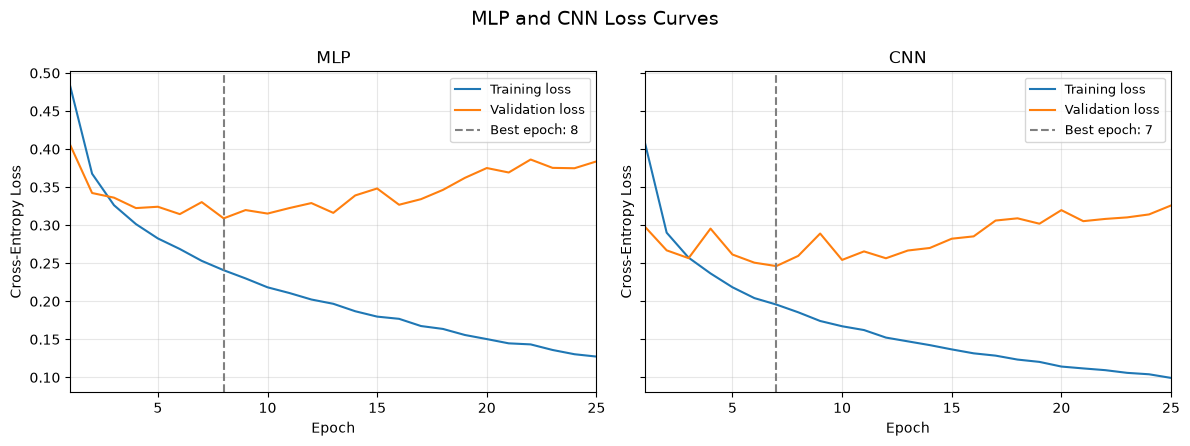

In [16]:
# Task 2-2: compare the loss curves

# Compare the existing histories without retraining either model.
mlp_train_losses = mlp_history["train_loss"]
mlp_val_losses = mlp_history["val_loss"]

cnn_train_losses = cnn_history["train_loss"]
cnn_val_losses = cnn_history["val_loss"]

mlp_epochs = range(1, len(mlp_train_losses) + 1)
cnn_epochs = range(1, len(cnn_train_losses) + 1)

# Use a shared loss scale so the two panels can be compared directly.
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharey=True
)

axes[0].plot(
    mlp_epochs,
    mlp_train_losses,
    label="Training loss",
    color="tab:blue"
)

axes[0].plot(
    mlp_epochs,
    mlp_val_losses,
    label="Validation loss",
    color="tab:orange"
)

axes[0].axvline(
    mlp_history["best_epoch"],
    color="gray",
    linestyle="--",
    label=f"Best epoch: {mlp_history['best_epoch']}"
)

axes[0].set_title("MLP")

axes[1].plot(
    cnn_epochs,
    cnn_train_losses,
    label="Training loss",
    color="tab:blue"
)

axes[1].plot(
    cnn_epochs,
    cnn_val_losses,
    label="Validation loss",
    color="tab:orange"
)

axes[1].axvline(
    cnn_history["best_epoch"],
    color="gray",
    linestyle="--",
    label=f"Best epoch: {cnn_history['best_epoch']}"
)

axes[1].set_title("CNN")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[0].set_xlim(1, len(mlp_train_losses))
axes[1].set_xlim(1, len(cnn_train_losses))

fig.suptitle("MLP and CNN Loss Curves", fontsize=14)

plt.tight_layout()
plt.show()


MLP parameters: 101,770
CNN parameters: 20,586


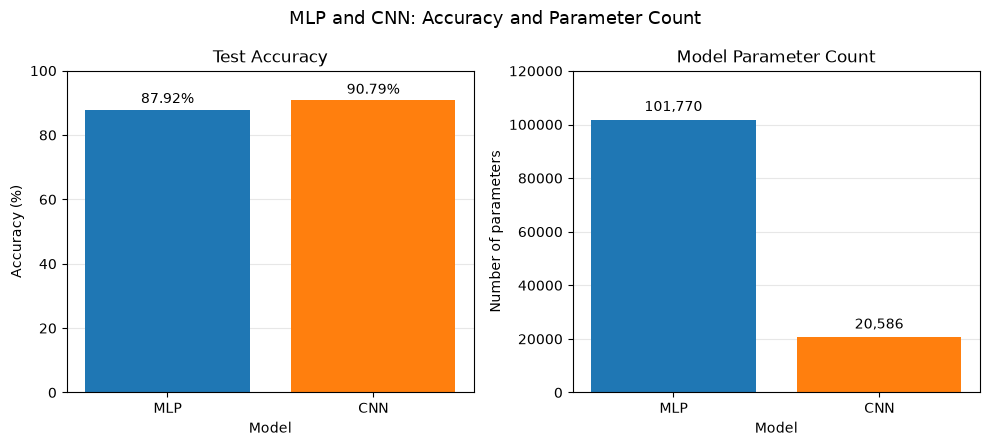

In [17]:
# Task 2-2: compare test accuracy and parameter count

model_names = ["MLP", "CNN"]

# Convert the reported accuracies to percentages for display.
test_accuracies = [
    mlp_test_acc * 100,
    cnn_test_acc * 100
]

# Count model parameters; BatchNorm running statistics are buffers, not parameters.
mlp_params = sum(p.numel() for p in mlp_model.parameters())
cnn_params = sum(p.numel() for p in cnn_model.parameters())

parameter_counts = [mlp_params, cnn_params]

print(f"MLP parameters: {mlp_params:,}")
print(f"CNN parameters: {cnn_params:,}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

colors = ["tab:blue", "tab:orange"]

# Use the same model colours in both panels.
accuracy_bars = axes[0].bar(
    model_names,
    test_accuracies,
    color=colors
)

axes[0].set_title("Test Accuracy")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)

for bar, accuracy in zip(accuracy_bars, test_accuracies):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )
parameter_bars = axes[1].bar(
    model_names,
    parameter_counts,
    color=colors
)

axes[1].set_title("Model Parameter Count")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Number of parameters")
axes[1].set_ylim(0, max(parameter_counts) * 1.18)

offset = max(parameter_counts) * 0.02

for bar, count in zip(parameter_bars, parameter_counts):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        count + offset,
        f"{count:,}",
        ha="center",
        va="bottom"
    )

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("MLP and CNN: Accuracy and Parameter Count", fontsize=13)

plt.tight_layout()
plt.show()


---
# Task 3: Controlled Experiments

## Task 3-1: Nonlinear Activation

Train your Task 2-1 architecture three times, swapping only the activation function with your own choice.


Activation: ReLU


Epoch 1/25 | Train loss: 0.4094 | Val loss: 0.2983


Epoch 2/25 | Train loss: 0.2902 | Val loss: 0.2669


Epoch 3/25 | Train loss: 0.2573 | Val loss: 0.2567


Epoch 4/25 | Train loss: 0.2366 | Val loss: 0.2955


...

Epoch 21/25 | Train loss: 0.1078 | Val loss: 0.2789


Epoch 22/25 | Train loss: 0.1027 | Val loss: 0.2941


Epoch 23/25 | Train loss: 0.0993 | Val loss: 0.2937


Epoch 24/25 | Train loss: 0.0979 | Val loss: 0.2933


Epoch 25/25 | Train loss: 0.0952 | Val loss: 0.3004

Record checks:

Activation: ReLU
Records (train / validation / gradient): 25 25 25
Best epoch: 7
Best validation loss: 0.2462
First gradient norm: 0.7289
Last gradient norm: 1.2790

Activation: Sigmoid
Records (train / validation / gradient): 25 25 25
Best epoch: 12
Best validation loss: 0.2292
First gradient norm: 0.6206
Last gradient norm: 1.5296

Activation: Tanh
Records (train / validation / gradient): 25 25 25
Best epoch: 7
Best validation loss: 0.2422
First gradient norm: 0.9594
Last gradient norm: 1.8887


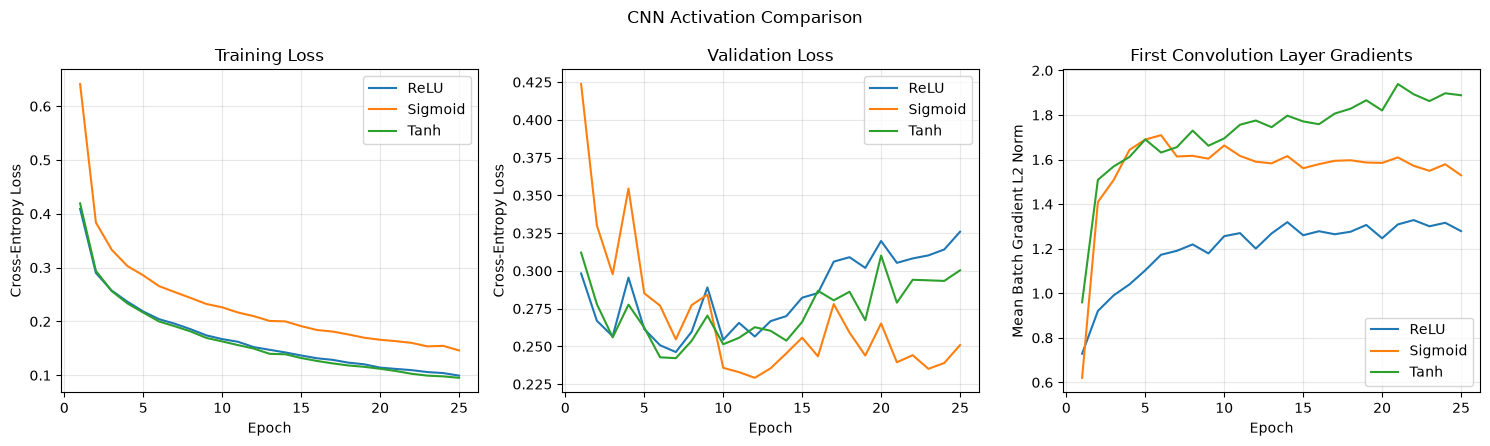

In [18]:
# Task 3-1: compare activation functions

# Change only the activation while keeping the CNN structure and settings fixed.
activation_types = {
    "ReLU": nn.ReLU,
    "Sigmoid": nn.Sigmoid,
    "Tanh": nn.Tanh
}

activation_histories = {}

for name, activation_class in activation_types.items():
    print(f"\nActivation: {name}")

    # Reset the seed so each run starts from the same initial weights.
    torch.manual_seed(SEED_TASK2)

    activation_model = SimpleCNN(num_classes=10).to(device)

    # The forward pass calls this module after both BatchNorm layers.
    activation_model.relu = activation_class()

    # Track the first convolutional layer as an early-layer gradient diagnostic.
    activation_model, activation_history = train_model(
        model=activation_model,
        X_tr=X_train,
        y_tr=y_train,
        X_va=X_val,
        y_va=y_val,
        epochs=25,
        lr=1e-3,
        batch_size=64,
        record_grad_norm_layer=activation_model.conv1,
        weight_decay=0.0
    )

    activation_histories[name] = activation_history

# Check that loss and gradient records cover every epoch.
print("\nRecord checks:")

for name, history in activation_histories.items():
    print(f"\nActivation: {name}")
    print(
        "Records (train / validation / gradient):",
        len(history["train_loss"]),
        len(history["val_loss"]),
        len(history["grad_norm"])
    )
    print(f"Best epoch: {history['best_epoch']}")
    print(f"Best validation loss: {history['best_val_loss']:.4f}")
    print(f"First gradient norm: {history['grad_norm'][0]:.4f}")
    print(f"Last gradient norm: {history['grad_norm'][-1]:.4f}")

# Inspect loss and gradient trends together when assessing vanishing gradients.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for name, history in activation_histories.items():
    epoch_numbers = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(
        epoch_numbers,
        history["train_loss"],
        label=name
    )
    axes[1].plot(
        epoch_numbers,
        history["val_loss"],
        label=name
    )
    axes[2].plot(
        epoch_numbers,
        history["grad_norm"],
        label=name
    )

axes[0].set_title("Training Loss")
axes[1].set_title("Validation Loss")
axes[2].set_title("First Convolution Layer Gradients")

axes[0].set_ylabel("Cross-Entropy Loss")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[2].set_ylabel("Mean Batch Gradient L2 Norm")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("CNN Activation Comparison")
plt.tight_layout()
plt.show()


**Explain whether vanishing gradient occurs during the training. If not, explain what you have done (not necessarily anything additional) to prevent it from happening. If so, explain the potential reasons.** (at most 80 words)
- Answer:No clear evidence of vanishing gradients was observed across the ReLU, Sigmoid and Tanh runs. Training loss decreased for all three, while the first convolutional layer’s mean gradient norm generally increased or remained stable rather than approaching zero. The shallow architecture and batch normalization retained in all runs may have helped maintain gradient flow. However, these aggregate measurements from one layer cannot rule out vanishing gradients in individual parameters or other layers.

## Task 3-2: Regularization

Train your Task 2-1 architecture with no explicit regularization, L2 applied, and Dropout applied.

In [19]:
# Task 3-2: compare regularisation settings

# Compare no explicit regularisation, L2, and dropout as separate settings.
regularization_configs = {
    "Baseline": {
        "weight_decay": 0.0,
        "dropout": None
    },
    "L2": {
        "weight_decay": 1e-4,
        "dropout": None
    },
    "Dropout": {
        "weight_decay": 0.0,
        "dropout": 0.5
    }
}

regularization_histories = {}

for name, config in regularization_configs.items():
    print(f"\nRegularization: {name}")

    # Reset the seed before creating each model.
    torch.manual_seed(SEED_TASK2)

    regularization_model = SimpleCNN(num_classes=10)

    # Apply dropout to the flattened features before the classifier.
    if config["dropout"] is not None:
        regularization_model.fc = nn.Sequential(
            nn.Dropout(p=config["dropout"]),
            regularization_model.fc
        )

    # Keep the learning rate, batch size and training duration unchanged.
    regularization_model, history = train_model(
        model=regularization_model,
        X_tr=X_train,
        y_tr=y_train,
        X_va=X_val,
        y_va=y_val,
        epochs=25,
        lr=1e-3,
        batch_size=64,
        weight_decay=config["weight_decay"]
    )

    regularization_histories[name] = history



Regularization: Baseline


Epoch 1/25 | Train loss: 0.4094 | Val loss: 0.2983


Epoch 2/25 | Train loss: 0.2902 | Val loss: 0.2669


Epoch 3/25 | Train loss: 0.2573 | Val loss: 0.2567


Epoch 4/25 | Train loss: 0.2366 | Val loss: 0.2955


...

Epoch 21/25 | Train loss: 0.2358 | Val loss: 0.2265


Epoch 22/25 | Train loss: 0.2358 | Val loss: 0.2269


Epoch 23/25 | Train loss: 0.2322 | Val loss: 0.2258


Epoch 24/25 | Train loss: 0.2298 | Val loss: 0.2291


Epoch 25/25 | Train loss: 0.2306 | Val loss: 0.2213



Regularization: Baseline
Training records: 25
Validation records: 25
Best epoch: 7
Best validation loss: 0.2462
Final training loss: 0.0993
Final validation loss: 0.3259

Regularization: L2
Training records: 25
Validation records: 25
Best epoch: 7
Best validation loss: 0.2428
Final training loss: 0.1066
Final validation loss: 0.2938

Regularization: Dropout
Training records: 25
Validation records: 25
Best epoch: 25
Best validation loss: 0.2213
Final training loss: 0.2306
Final validation loss: 0.2213


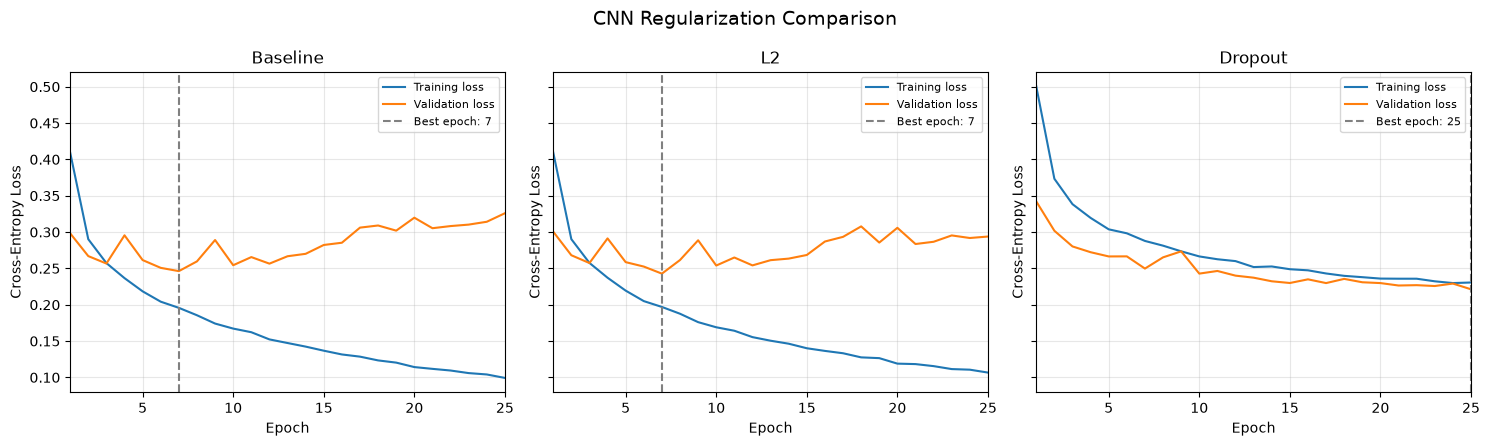

In [20]:
# Task 3-2: summarise and plot the regularisation experiments

# Compare the best validation result with the losses at the final epoch.
for name, history in regularization_histories.items():
    print(f"\nRegularization: {name}")
    print(f"Training records: {len(history['train_loss'])}")
    print(f"Validation records: {len(history['val_loss'])}")
    print(f"Best epoch: {history['best_epoch']}")
    print(f"Best validation loss: {history['best_val_loss']:.4f}")
    print(f"Final training loss: {history['train_loss'][-1]:.4f}")
    print(f"Final validation loss: {history['val_loss'][-1]:.4f}")

# Keep the vertical scale shared across the three experiments.
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharey=True
)

for ax, (name, history) in zip(
    axes, regularization_histories.items()
):
    epoch_numbers = range(1, len(history["train_loss"]) + 1)

    ax.plot(
        epoch_numbers,
        history["train_loss"],
        label="Training loss",
        color="tab:blue"
    )

    ax.plot(
        epoch_numbers,
        history["val_loss"],
        label="Validation loss",
        color="tab:orange"
    )

    # Mark the best validation epoch separately for each run.
    ax.axvline(
        history["best_epoch"],
        color="gray",
        linestyle="--",
        label=f"Best epoch: {history['best_epoch']}"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.set_xlim(1, len(history["train_loss"]))
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.suptitle("CNN Regularization Comparison", fontsize=14)
plt.tight_layout()
plt.show()


**Explain whether overfitting occurs during the training. If not, explain what you have done (not necessarily anything additional) to prevent it from happening. If so, explain the potential reasons.** (at most 80 words)
- Answer:Baseline and L2 showed overfitting after epoch 7: training loss continued falling while validation loss rose from 0.2462 to 0.3259 and from 0.2428 to 0.2938, respectively. L2 reduced but did not eliminate this deterioration. Dropout showed no clear overfitting within 25 epochs, reaching its lowest validation loss of 0.2213 at epoch 25. Continued fitting to training-specific patterns may explain the first two runs, whereas randomly dropping features may have constrained such fitting.

---
# Task 4: Diagnosis and Model Comparison

## Task 4-1: Confusion Matrix

Identify the pair of classes that your Task 2-1 CNN confuses most frequently, based on the confusion matrix
generated from your own results.

**Describe the visible characteristics of one misclassified example from each of the two identified classes.** (at most 60 words)
- Answer:T-shirt/top and Shirt were the most frequently confused pair, with 215 errors across both directions. The T-shirt/top example (index 359) had a straight torso outline and dark cutout-like shapes near the neckline. The Shirt example (index 40) had short sleeves and faint button-like marks along a central vertical strip.

Number of predictions: 10000
CNN test accuracy check: 90.79%


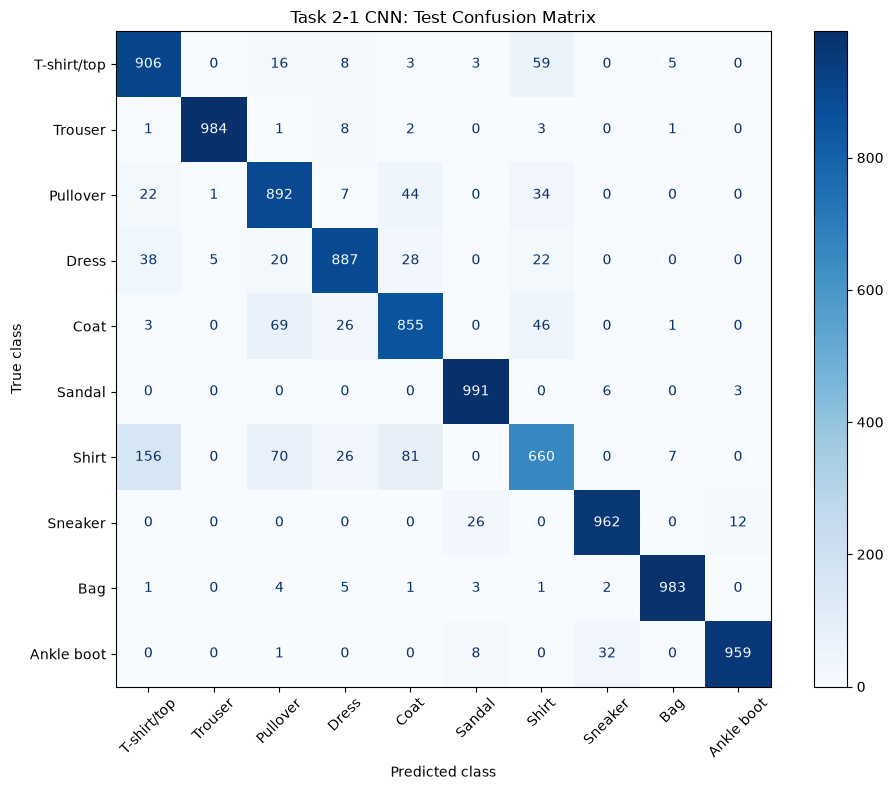

Most-confused pair: T-shirt/top and Shirt
T-shirt/top → Shirt: 59
Shirt → T-shirt/top: 156
Combined confusion count: 215


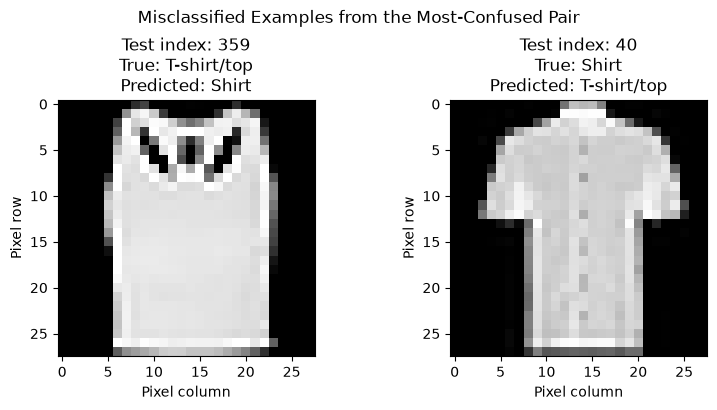

In [21]:
# Task 4-1: find the most-confused pair and inspect example errors

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = train_full.classes

# Use the original Task 2-1 CNN, not an activation or regularisation variant.
cnn_model.eval()
prediction_batches = []

# Predict in batches to limit inference memory use.
with torch.no_grad():
    for start in range(0, len(X_test), 256):
        inputs = X_test[start:start + 256].to(device)

        logits = cnn_model(inputs)
        predictions = logits.argmax(dim=1)

        prediction_batches.append(predictions.cpu())

cnn_test_predictions = torch.cat(prediction_batches)
cnn_test_targets = y_test.detach().cpu()

accuracy_check = (
    cnn_test_predictions == cnn_test_targets
).float().mean().item()

print("Number of predictions:", len(cnn_test_predictions))
print(f"CNN test accuracy check: {accuracy_check:.2%}")


# Rows represent true classes and columns represent predicted classes.
cm = confusion_matrix(
    cnn_test_targets.numpy(),
    cnn_test_predictions.numpy(),
    labels=range(len(class_names))
)

cm_fig, cm_ax = plt.subplots(figsize=(10, 8))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

cm_display.plot(
    ax=cm_ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=True
)

cm_ax.set_title("Task 2-1 CNN: Test Confusion Matrix")
cm_ax.set_xlabel("Predicted class")
cm_ax.set_ylabel("True class")

cm_fig.tight_layout()
plt.show()
plt.close(cm_fig)


# Combine both error directions when ranking pairs of classes.
pair_counts = cm + cm.T

# Exclude correct predictions and count each unordered pair only once.
upper_pair_counts = np.triu(pair_counts, k=1)

class_a, class_b = np.unravel_index(
    np.argmax(upper_pair_counts),
    upper_pair_counts.shape
)

class_a = int(class_a)
class_b = int(class_b)
confused_pair = (class_a, class_b)

if upper_pair_counts[class_a, class_b] == 0:
    raise ValueError("No confused class pair was found.")

print(
    "Most-confused pair:",
    class_names[class_a],
    "and",
    class_names[class_b]
)

print(
    f"{class_names[class_a]} → {class_names[class_b]}:",
    cm[class_a, class_b]
)

print(
    f"{class_names[class_b]} → {class_names[class_a]}:",
    cm[class_b, class_a]
)

print(
    "Combined confusion count:",
    pair_counts[class_a, class_b]
)


# Select one real error from each of the two true classes.
misclassified_indices = []

for true_class, other_class in [
    (class_a, class_b),
    (class_b, class_a)
]:
    candidates = torch.where(
        (cnn_test_targets == true_class)
        & (cnn_test_predictions == other_class)
    )[0]

    # If that direction has no errors, try another error from the same true class.
    if candidates.numel() == 0:
        candidates = torch.where(
            (cnn_test_targets == true_class)
            & (cnn_test_predictions != true_class)
        )[0]

    if candidates.numel() == 0:
        raise ValueError(
            f"No misclassified example exists for "
            f"{class_names[true_class]}."
        )

    misclassified_indices.append(int(candidates[0].item()))


# Create a separate figure so these examples do not reuse earlier axes.
example_fig, example_axes = plt.subplots(
    1, 2, figsize=(8, 4)
)

for ax, index in zip(example_axes, misclassified_indices):
    standardized_image = X_test[index].detach().cpu()

    # Undo standardisation for display only; model inputs remain standardised.
    display_image = (
        standardized_image * train_std.detach().cpu()
        + train_mean.detach().cpu()
    )
    display_image = display_image.squeeze(0).clamp(0, 1)

    true_class = int(cnn_test_targets[index].item())
    predicted_class = int(cnn_test_predictions[index].item())

    ax.imshow(
        display_image.numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(
        f"Test index: {index}\n"
        f"True: {class_names[true_class]}\n"
        f"Predicted: {class_names[predicted_class]}"
    )

    ax.set_xlabel("Pixel column")
    ax.set_ylabel("Pixel row")

example_fig.suptitle(
    "Misclassified Examples from the Most-Confused Pair"
)

example_fig.tight_layout()
plt.show()
plt.close(example_fig)


## Task 4-2: Case Analysis

Select and examine one of the misclassified images identified above.

**Provide an assessment of the model’s confidence in its prediction for this example, based on the corresponding model output.** (at most 60 words)
- Answer:For test image 359, the CNN incorrectly predicted Shirt with a softmax probability of 52.73%, while the true class, T-shirt/top, received 34.98%. The 17.75-percentage-point gap indicates a preference for Shirt, but substantial probability remained on the true class. This suggests moderate confidence with considerable uncertainty, rather than a highly confident error.

Test index: 359
True class: T-shirt/top
Predicted class: Shirt
Predicted-class probability: 52.73%
True-class probability: 34.98%
Second-highest class: T-shirt/top
Second-highest probability: 34.98%
Top-two probability gap: 17.75 percentage points


Sum of probabilities: 1.000000

All class probabilities:
T-shirt/top: 34.9784%
Trouser: 0.0065%
Pullover: 9.3938%
Dress: 2.6672%
Coat: 0.2245%
Sandal: 0.0000%
Shirt: 52.7260%
Sneaker: 0.0000%
Bag: 0.0036%
Ankle boot: 0.0000%


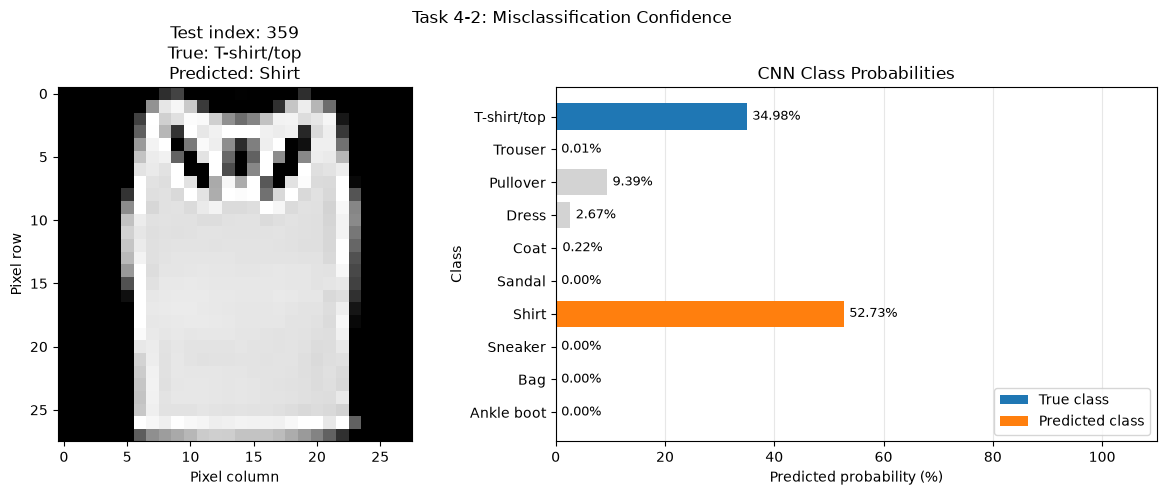

In [22]:
# Task 4-2: inspect the probabilities for one misclassified image

from matplotlib.patches import Patch

# Reuse an error found in Task 4-1 and preserve its batch dimension.
selected_index = misclassified_indices[0]
selected_input = X_test[
    selected_index:selected_index + 1
].to(device)

true_class = int(y_test[selected_index].item())

# Keep BatchNorm in evaluation mode for this single-image prediction.
cnn_model.eval()

with torch.no_grad():
    logits = cnn_model(selected_input)

    # Convert the logits to a distribution over the ten classes.
    probabilities = torch.softmax(logits, dim=1)

probabilities = probabilities.squeeze(0).cpu()

predicted_class = int(probabilities.argmax().item())
predicted_probability = probabilities[predicted_class].item()
true_probability = probabilities[true_class].item()

# Compare the leading two probabilities when describing confidence.
top_probabilities, top_classes = torch.topk(probabilities, k=2)

second_class = int(top_classes[1].item())
second_probability = top_probabilities[1].item()

probability_margin = (
    top_probabilities[0] - top_probabilities[1]
).item()

# Catch a stale example if the model has changed since Task 4-1.
if predicted_class == true_class:
    raise ValueError(
        "The selected image is no longer misclassified. "
        "Check the model and rerun Task 4-1."
    )

print("Test index:", selected_index)
print("True class:", class_names[true_class])
print("Predicted class:", class_names[predicted_class])

print(f"Predicted-class probability: {predicted_probability:.2%}")
print(f"True-class probability: {true_probability:.2%}")

print("Second-highest class:", class_names[second_class])
print(f"Second-highest probability: {second_probability:.2%}")

print(
    "Top-two probability gap:",
    f"{probability_margin * 100:.2f} percentage points"
)

print(f"Sum of probabilities: {probabilities.sum().item():.6f}")

# Show every class, including alternatives to the predicted and true labels.
print("\nAll class probabilities:")
for class_id, probability in enumerate(probabilities):
    print(f"{class_names[class_id]}: {probability.item():.4%}")

# Reverse standardisation only for the image shown in the figure.
display_image = (
    X_test[selected_index].detach().cpu()
    * train_std.detach().cpu()
    + train_mean.detach().cpu()
)
display_image = display_image.squeeze(0).clamp(0, 1)

probability_percentages = probabilities.numpy() * 100

# Highlight the true and predicted classes; keep the others neutral.
bar_colors = ["lightgray"] * len(class_names)
bar_colors[true_class] = "tab:blue"
bar_colors[predicted_class] = "tab:orange"

case_fig, case_axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

case_axes[0].imshow(
    display_image.numpy(),
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

case_axes[0].set_title(
    f"Test index: {selected_index}\n"
    f"True: {class_names[true_class]}\n"
    f"Predicted: {class_names[predicted_class]}"
)
case_axes[0].set_xlabel("Pixel column")
case_axes[0].set_ylabel("Pixel row")

bars = case_axes[1].barh(
    class_names,
    probability_percentages,
    color=bar_colors
)

case_axes[1].invert_yaxis()
case_axes[1].set_xlim(0, 110)
case_axes[1].set_xticks([0, 20, 40, 60, 80, 100])
case_axes[1].set_xlabel("Predicted probability (%)")
case_axes[1].set_ylabel("Class")
case_axes[1].set_title("CNN Class Probabilities")

for bar, percentage in zip(bars, probability_percentages):
    case_axes[1].text(
        percentage + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.2f}%",
        va="center",
        fontsize=9
    )

case_axes[1].legend(
    handles=[
        Patch(facecolor="tab:blue", label="True class"),
        Patch(facecolor="tab:orange", label="Predicted class")
    ],
    loc="lower right"
)

case_axes[1].set_axisbelow(True)
case_axes[1].grid(axis="x", alpha=0.3)

case_fig.suptitle("Task 4-2: Misclassification Confidence")
case_fig.tight_layout()

plt.show()
plt.close(case_fig)


## Task 4-3: Diagnosing the Cause

First assess whether class imbalance in your own training split could reasonably explain the observed confusion between the identified classes. If class imbalance does not provide an adequate explanation, investigate at least two other distinct and plausible reasons for the confusion.

**Sample counts and imbalance judgement**
- Answer:The training split contained 5,069 T-shirt/top images and 5,077 Shirt images, differing by only eight samples, or 0.16% of their mean count. The larger-to-smaller count ratio was 1.0016. These nearly equal counts make class-frequency imbalance an unlikely explanation for the observed confusion, although they do not establish equal visual diversity.

Training-set class counts:
T-shirt/top: 5,069
Trouser: 5,120
Pullover: 5,111
Dress: 5,111
Coat: 5,104
Sandal: 5,109
Shirt: 5,077
Sneaker: 5,057
Bag: 5,113
Ankle boot: 5,129

Selected class pair:
T-shirt/top: 5,069
Shirt: 5,077
Larger/smaller count ratio: 1.0016
Absolute count difference: 8
Difference relative to pair mean: 0.16%


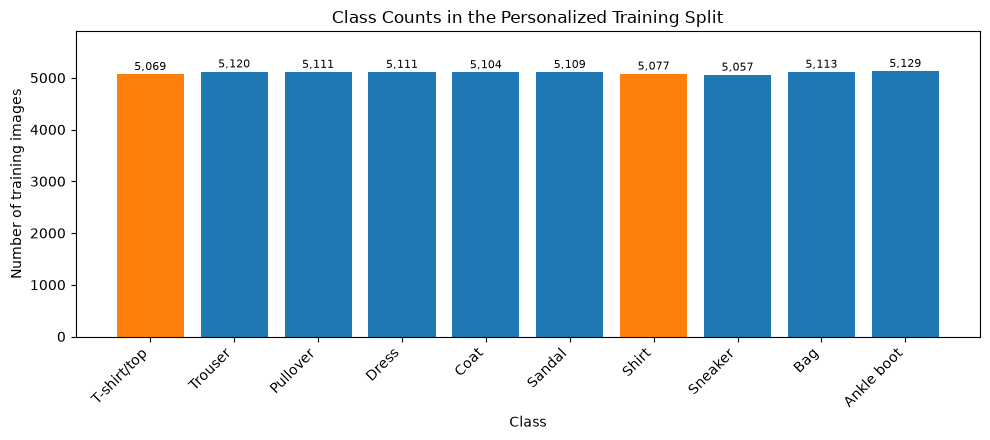

In [23]:
# Task 4-3: check class counts in the training split

class_a, class_b = confused_pair
training_labels = y_train.detach().cpu()
test_labels = y_test.detach().cpu()

# Count labels in the actual training split, not in the original full dataset.
class_counts = torch.bincount(
    training_labels,
    minlength=len(class_names)
)

print("Training-set class counts:")
for class_id, count in enumerate(class_counts):
    print(f"{class_names[class_id]}: {count.item():,}")

count_a = int(class_counts[class_a].item())
count_b = int(class_counts[class_b].item())

if min(count_a, count_b) == 0:
    raise ValueError("One of the selected classes has no training samples.")

# Report the count ratio and the difference relative to the pair mean.
count_ratio = max(count_a, count_b) / min(count_a, count_b)
relative_difference = (
    abs(count_a - count_b) / ((count_a + count_b) / 2) * 100
)

print("\nSelected class pair:")
print(f"{class_names[class_a]}: {count_a:,}")
print(f"{class_names[class_b]}: {count_b:,}")
print(f"Larger/smaller count ratio: {count_ratio:.4f}")
print(f"Absolute count difference: {abs(count_a - count_b)}")
print(f"Difference relative to pair mean: {relative_difference:.2f}%")

count_fig, count_ax = plt.subplots(figsize=(10, 4.5))

# Highlight the confused pair while retaining the other classes for context.
count_colors = [
    "tab:orange" if i in confused_pair else "tab:blue"
    for i in range(len(class_names))
]

count_bars = count_ax.bar(
    class_names,
    class_counts.numpy(),
    color=count_colors
)

for bar, count in zip(count_bars, class_counts.tolist()):
    count_ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 30,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

count_ax.set_title("Class Counts in the Personalized Training Split")
count_ax.set_xlabel("Class")
count_ax.set_ylabel("Number of training images")
count_ax.set_ylim(0, class_counts.max().item() * 1.15)
plt.setp(count_ax.get_xticklabels(), rotation=45, ha="right")

count_fig.tight_layout()
plt.show()
plt.close(count_fig)


**First reason** (at most 60 words)
- Answer:Cross-class visual overlap may contribute to confusion. With 500 training references per class, the nearest reference belonged to the other class for 54.88% of mutually confused images versus 16.41% of correctly classified images. For image 40, other-class RMSE was 0.1087 versus 0.1613 within-class. Pixel similarity supports this explanation but does not establish causation.

Reference images per class: 500


Test images from the selected pair: 2000

Correctly classified: n=1566
Nearest other-class image closer than nearest same-class image: 16.41%
Mean nearest same-class RMSE: 0.1465
Mean nearest other-class RMSE: 0.1790

Mutually confused: n=215
Nearest other-class image closer than nearest same-class image: 54.88%
Mean nearest same-class RMSE: 0.1696
Mean nearest other-class RMSE: 0.1650


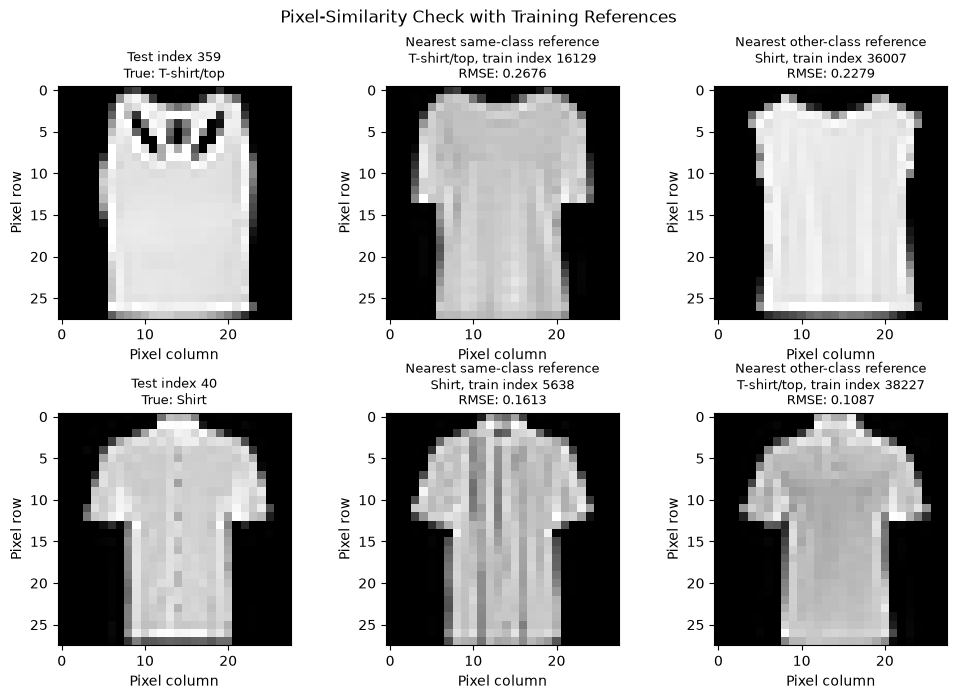

In [24]:
# Task 4-3: compare pixel similarity with training references

mean_value = float(train_mean.item())
std_value = float(train_std.item())

# Use a separate generator so reference sampling does not reset training RNG state.
reference_generator = torch.Generator().manual_seed(SEED_TASK2)

# Sample equal numbers from both classes for a balanced reference comparison.
reference_size = min(500, count_a, count_b)
reference_indices = {}

for class_id in confused_pair:
    available = torch.where(training_labels == class_id)[0]
    order = torch.randperm(
        len(available),
        generator=reference_generator
    )
    reference_indices[class_id] = available[order[:reference_size]]

# Measure pixel RMSE on the original [0, 1] intensity scale.
reference_pixels = {}

for class_id in confused_pair:
    indices = reference_indices[class_id].to(X_train.device)
    images = X_train[indices].detach().cpu()
    images = images * std_value + mean_value
    reference_pixels[class_id] = images.flatten(start_dim=1)

# Restrict this analysis to test images whose true label belongs to the pair.
pair_test_indices = torch.where(
    (test_labels == class_a) | (test_labels == class_b)
)[0]

pair_inputs = X_test[
    pair_test_indices.to(X_test.device)
].detach().cpu()

pair_true = test_labels[pair_test_indices]


def task43_probabilities(images, batch_size=256):
    """Evaluate the unchanged Task 2-1 CNN."""
    cnn_model.eval()
    batches = []

    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            logits = cnn_model(
                images[start:start + batch_size].to(device)
            )
            batches.append(torch.softmax(logits, dim=1).cpu())

    return torch.cat(batches)


pair_probabilities = task43_probabilities(pair_inputs)
pair_predictions = pair_probabilities.argmax(dim=1)

pair_pixels = (
    pair_inputs * std_value + mean_value
).flatten(start_dim=1)

# Find the nearest sampled training image in each class.
nearest_distances = {}
nearest_train_indices = {}

for reference_class in confused_pair:
    distance_batches = []
    index_batches = []

    # Batch the distance calculation to avoid storing one large distance matrix.
    for start in range(0, len(pair_pixels), 128):
        distances = torch.cdist(
            pair_pixels[start:start + 128],
            reference_pixels[reference_class],
            p=2
        )

        minimum_distances, nearest_positions = distances.min(dim=1)

        # Divide Euclidean distance by sqrt(pixel count) to obtain RMSE.
        distance_batches.append(
            minimum_distances / (pair_pixels.shape[1] ** 0.5)
        )
        index_batches.append(
            reference_indices[reference_class][nearest_positions]
        )

    nearest_distances[reference_class] = torch.cat(distance_batches)
    nearest_train_indices[reference_class] = torch.cat(index_batches)

same_class_distance = torch.where(
    pair_true == class_a,
    nearest_distances[class_a],
    nearest_distances[class_b]
)

other_class_distance = torch.where(
    pair_true == class_a,
    nearest_distances[class_b],
    nearest_distances[class_a]
)

# Test whether the nearest reference from the other class is closer.
other_class_closer = other_class_distance < same_class_distance

# Compare correct predictions with errors between these two classes only.
correct_mask = pair_predictions == pair_true
mutual_error_mask = (
    ((pair_true == class_a) & (pair_predictions == class_b))
    | ((pair_true == class_b) & (pair_predictions == class_a))
)

print(f"Reference images per class: {reference_size}")
print(f"Test images from the selected pair: {len(pair_true)}")

for group_name, mask in [
    ("Correctly classified", correct_mask),
    ("Mutually confused", mutual_error_mask)
]:
    number = int(mask.sum().item())
    print(f"\n{group_name}: n={number}")

    if number == 0:
        print("No samples in this group.")
        continue

    closer_percentage = (
        other_class_closer[mask].float().mean().item() * 100
    )

    print(
        "Nearest other-class image closer than nearest same-class image:",
        f"{closer_percentage:.2f}%"
    )
    print(
        "Mean nearest same-class RMSE:",
        f"{same_class_distance[mask].mean().item():.4f}"
    )
    print(
        "Mean nearest other-class RMSE:",
        f"{other_class_distance[mask].mean().item():.4f}"
    )

# Show both selected errors alongside their nearest sampled references.
similarity_fig, similarity_axes = plt.subplots(
    2, 3, figsize=(10, 7)
)

for row, test_index in enumerate(misclassified_indices):
    position = int(
        torch.where(pair_test_indices == test_index)[0][0].item()
    )

    true_class = int(pair_true[position].item())
    other_class = class_b if true_class == class_a else class_a

    same_index = int(
        nearest_train_indices[true_class][position].item()
    )
    other_index = int(
        nearest_train_indices[other_class][position].item()
    )

    source_images = [
        X_test[test_index],
        X_train[same_index],
        X_train[other_index]
    ]

    titles = [
        f"Test index {test_index}\n"
        f"True: {class_names[true_class]}",

        f"Nearest same-class reference\n"
        f"{class_names[true_class]}, train index {same_index}\n"
        f"RMSE: {nearest_distances[true_class][position]:.4f}",

        f"Nearest other-class reference\n"
        f"{class_names[other_class]}, train index {other_index}\n"
        f"RMSE: {nearest_distances[other_class][position]:.4f}"
    ]

    for ax, image, title in zip(
        similarity_axes[row], source_images, titles
    ):
        pixels = (
            image.detach().cpu() * std_value + mean_value
        ).squeeze(0).clamp(0, 1)

        ax.imshow(
            pixels.numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )
        ax.set_title(title, fontsize=9)
        ax.set_xlabel("Pixel column")
        ax.set_ylabel("Pixel row")

similarity_fig.suptitle("Pixel-Similarity Check with Training References")
similarity_fig.tight_layout()
plt.show()
plt.close(similarity_fig)


**Second reason** (at most 60 words)
- Answer:Sensitivity to local details may contribute to errors. Upper-centre masking reduced pair-subset accuracy from 78.30% to 70.30%, versus 75.65% with equal-area lower masking. However, it corrected image 359, raising its true-class probability from 34.98% to 81.98%. Thus, upper-region cues can influence errors in individual cases, although artificial occlusion prevents definitive causal attribution.

Equal-area masks: 8 x 12 pixels.
Mask value: training-set mean pixel intensity.
Results below concern only the two selected true classes.

Condition: Original
Accuracy on selected classes: 78.30%
T-shirt/top -> Shirt: 59
Shirt -> T-shirt/top: 156
Combined confusion count: 215
Mean true-class probability: 0.7299

Condition: Upper centre
Accuracy on selected classes: 70.30%
T-shirt/top -> Shirt: 31
Shirt -> T-shirt/top: 289
Combined confusion count: 320
Mean true-class probability: 0.6695
Originally incorrect, now correct: 64
Originally correct, now incorrect: 224
Mean change in true-class probability: -6.04 percentage points

Condition: Lower centre
Accuracy on selected classes: 75.65%
T-shirt/top -> Shirt: 37
Shirt -> T-shirt/top: 198
Combined confusion count: 235
Mean true-class probability: 0.7041
Originally incorrect, now correct: 54
Originally correct, now incorrect: 107
Mean change in true-class probability: -2.58 percentage points


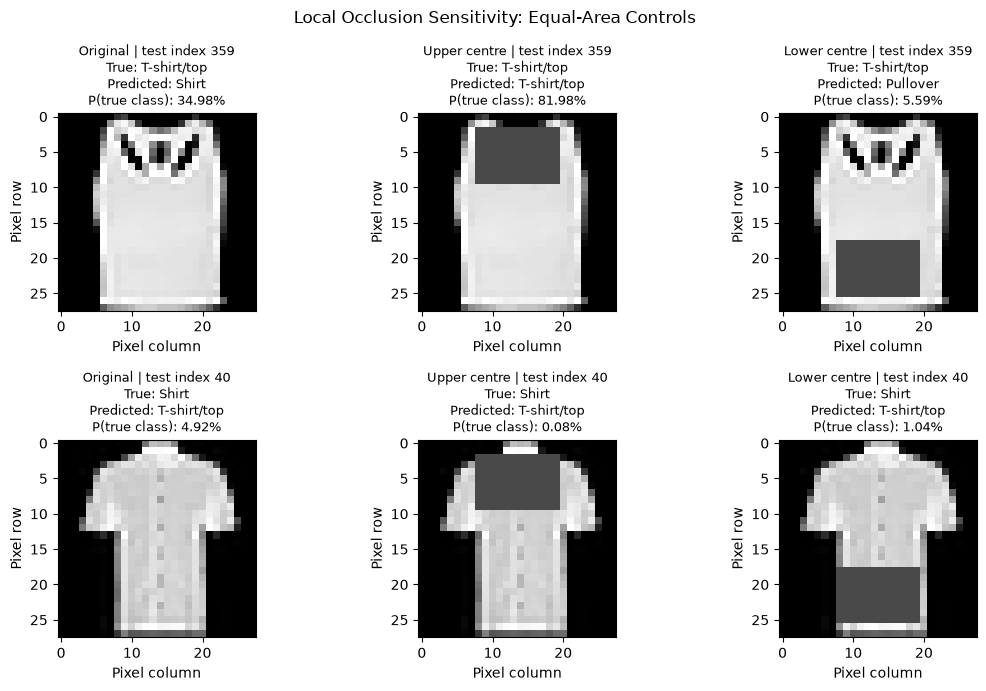

In [25]:
# Task 4-3: compare sensitivity to two masked regions

# Compare upper and lower regions with the same 8 x 12 pixel area.
occlusion_regions = {
    "Upper centre": (slice(2, 10), slice(8, 20)),
    "Lower centre": (slice(18, 26), slice(8, 20))
}


def apply_task43_mask(images, region):
    """Mask a region without modifying the original inputs."""

    # Work on a copy so the original test images remain unchanged.
    masked_images = images.clone()
    rows, columns = region

    # Zero after standardisation corresponds to the training-set mean intensity.
    masked_images[:, :, rows, columns] = 0.0

    return masked_images


# Reuse the unmasked predictions as the reference condition.
condition_probabilities = {
    "Original": pair_probabilities
}

# Change only the masked region while keeping the trained CNN fixed.
for condition, region in occlusion_regions.items():
    masked_inputs = apply_task43_mask(pair_inputs, region)
    condition_probabilities[condition] = task43_probabilities(
        masked_inputs
    )

original_correct = pair_predictions == pair_true
sample_rows = torch.arange(len(pair_true))

print("Equal-area masks: 8 x 12 pixels.")
print("Mask value: training-set mean pixel intensity.")
print("Results below concern only the two selected true classes.")

for condition, probabilities in condition_probabilities.items():
    predictions = probabilities.argmax(dim=1)
    correct = predictions == pair_true

    a_to_b = int((
        (pair_true == class_a) & (predictions == class_b)
    ).sum().item())

    b_to_a = int((
        (pair_true == class_b) & (predictions == class_a)
    ).sum().item())

    # Average the probability assigned to each image's own true class.
    mean_true_probability = probabilities[
        sample_rows, pair_true
    ].mean().item()

    print(f"\nCondition: {condition}")
    print(f"Accuracy on selected classes: {correct.float().mean():.2%}")
    print(f"{class_names[class_a]} -> {class_names[class_b]}: {a_to_b}")
    print(f"{class_names[class_b]} -> {class_names[class_a]}: {b_to_a}")
    print(f"Combined confusion count: {a_to_b + b_to_a}")
    print(f"Mean true-class probability: {mean_true_probability:.4f}")

    # Report both corrected errors and newly introduced errors.
    if condition != "Original":
        corrected = int(((~original_correct) & correct).sum().item())
        harmed = int((original_correct & (~correct)).sum().item())

        print(f"Originally incorrect, now correct: {corrected}")
        print(f"Originally correct, now incorrect: {harmed}")

        probability_change = (
            probabilities[sample_rows, pair_true]
            - pair_probabilities[sample_rows, pair_true]
        ).mean().item()

        print(
            "Mean change in true-class probability:",
            f"{probability_change * 100:+.2f} percentage points"
        )

# Use the same two examples to show how the masks affect individual predictions.
condition_names = list(condition_probabilities.keys())

occlusion_fig, occlusion_axes = plt.subplots(
    2, 3, figsize=(11, 7)
)

for row, test_index in enumerate(misclassified_indices):
    position = int(
        torch.where(pair_test_indices == test_index)[0][0].item()
    )
    true_class = int(pair_true[position].item())

    for column, condition in enumerate(condition_names):
        image_batch = pair_inputs[position:position + 1]

        if condition != "Original":
            image_batch = apply_task43_mask(
                image_batch,
                occlusion_regions[condition]
            )

        probabilities = condition_probabilities[condition][position]
        predicted_class = int(probabilities.argmax().item())
        true_probability = probabilities[true_class].item()

        pixels = (
            image_batch[0] * std_value + mean_value
        ).squeeze(0).clamp(0, 1)

        ax = occlusion_axes[row, column]
        ax.imshow(
            pixels.numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        ax.set_title(
            f"{condition} | test index {test_index}\n"
            f"True: {class_names[true_class]}\n"
            f"Predicted: {class_names[predicted_class]}\n"
            f"P(true class): {true_probability:.2%}",
            fontsize=9
        )
        ax.set_xlabel("Pixel column")
        ax.set_ylabel("Pixel row")

occlusion_fig.suptitle("Local Occlusion Sensitivity: Equal-Area Controls")
occlusion_fig.tight_layout()
plt.show()
plt.close(occlusion_fig)


# Formality and Readability

- The notebook and the PDF are both submitted, the PDF is exported from the
submitted notebook, and every code cell and its output are visible in it.
- The notebook shall be able to run from top to bottom in the given environment, with no
unhandled error traceback and no debug logging left behind. The environment shall be stated, especially
on whether the hardware used is stronger than the lab’s RTX 3090 based workstation.
- Every figure carries axis labels and a title and displays fully in the PDF, and no code is
cut off at the page edge.
- The whole notebook is written in English, commented and organized, with no
redundant or leftover content.
- Code overall is properly commented and organized across the notebook.
- For any other question, please refer to the coursework PDF document for more details.